<div style="display:flex; align-items:center; border-bottom:3px solid #662d91; padding-bottom:10px;">
  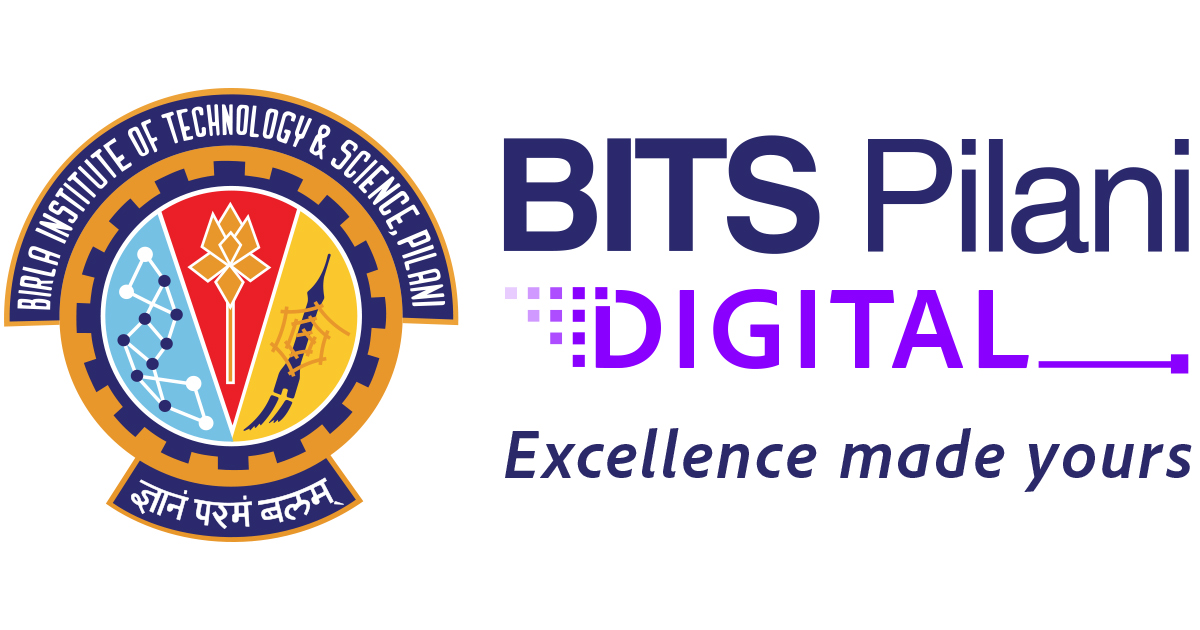
  <div>
    <h1 style="color:#003366; margin:0;">Lab 1: Probability and Distributions</h1>
    <p style="color:#662d91; margin:2px 0;"><b>Statistical Modelling and Inferencing (MDSDF401)</b></p>
    <p style="color:#555; margin:0;">Dr. Pushpendra Gupta &middot; BITS Pilani Digital</p>
  </div>
</div>

<p style="color:#cc3300; margin-top:10px;"><b>Experiential Learning Lab 1 &middot; Covers Week 1 &middot; Probability as Long-Run Frequency and the Basic Distributions</b></p>

## Introduction

Everyone "knows" that a fair coin lands heads with probability 0.5. But what does
that number actually tell us? It does not tell us what the next flip will be.
It tells us what happens **in the long run**. If the coin is flipped again and
again, the share of heads settles near 0.5.

This idea is called **probability as long-run relative frequency**. It is the
thread of this lab. It explains why probability is useful at all. An insurer
cannot say which customer will claim, and a factory cannot say which item will
be faulty. Both can say, with confidence, what share of a large batch will.

The lab has two parts.

- **Part A (Tasks 1 to 5)** is about the meaning of probability. You flip coins
  and roll dice by simulation, and watch relative frequencies settle.
- **Part B (Tasks 6 to 9)** is about the basic tools of Week 1. It covers scales
  of measurement, a little descriptive statistics, the PMF, PDF and CDF, and the
  Binomial, Poisson and Normal distributions. Each distribution is shown both
  ways: as a formula, and as the long-run frequency of a simulated experiment.

### Learning objectives

By the end of this lab you should be able to:

1. Explain what a probability means as a long-run relative frequency.
2. Explain why the **proportion** of heads settles while the **count** of heads
   can still wander.
3. Explain why a coin has no memory, and why streaks are normal.
4. Estimate probabilities by frequency when outcomes are not equally likely.
5. Place a variable on the nominal, ordinal, interval or ratio scale, and say
   which summaries that scale permits.
6. Read a PMF, a PDF and a CDF, and use the CDF for range questions.
7. Use the Binomial, Poisson, Exponential and Normal distributions on simple
   questions, and say when one may stand in for another.

## Before You Start

**You should already have seen** the Week 1 recorded sessions, in particular
*Revision for Basic Probability*, *Random Variable and Distributions* and
*Probability and Distribution*. The coin-flipping demonstration in the first of
these is the starting point of Part A.

**Reading Material Week 1** is the companion to this lab. Several examples below
are its own worked examples, so you can check the notebook against the page.

| Reading Material Week 1 section | Lab task |
| --- | --- |
| Basic Probability Concepts; The Law of Large Numbers | Tasks 1 to 5 |
| (the Week 1 videos on types of data and descriptive statistics) | Task 6 |
| Random Variables; Probability Functions: PMF, PDF, CDF | Task 7 |
| Discrete Distributions: Binomial and Poisson | Task 8 |
| Continuous Distributions: The Normal | Task 9 |

**Running this notebook:**

- Open it in **Google Colab** and choose *Runtime > Run all*, or run it in
  Jupyter. Every library used is already installed on Colab.
- Every task has a short theory block, one to three code cells, and a
  **TO DO** block. The TO DO asks you to change one thing, re-run, and observe.
- Each simulation cell restarts the random generator from the same seed, so a
  cell gives the same numbers every time you run it. Change the seed in a cell
  to see a fresh run of the same experiment.
- Tasks 8 and 9 contain **slider** cells. The saved notebook shows the default
  picture. When you run the cell yourself, sliders appear under it, and the
  picture below the sliders changes as you move them.

In [ ]:
# Setup: libraries, the seed for this lab, and the colours used in the plots.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider

SEED = 17

NAVY, PURPLE, ORANGE, PALE, RED = "#003366", "#662d91", "#ff9900", "#cfe2f3", "#b03a2e"
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Setup complete. Seed =", SEED)

---

# Part A: What a Probability Means

## Task 1: The Running Proportion of Heads

When all outcomes are equally likely, the **classical** definition gives a
probability by counting:

$$P(A) = \frac{\text{number of favourable outcomes}}{\text{total number of outcomes}}.$$

For a fair coin this gives $P(\text{heads}) = 1/2$. The **frequency** view says
what this number means in practice. Repeat the experiment $n$ times and record
the share of trials on which the event happened:

$$\text{relative frequency of } A = \frac{\text{number of times } A \text{ occurred}}{n}.$$

As $n$ grows, this share settles near $P(A)$. This is the **law of large
numbers**, which the video showed with a "flip 100 coins" button. Below, the
computer flips a fair coin 10,000 times and tracks the share of heads after
every flip.

In [ ]:
rng = np.random.default_rng(SEED)
n_flips = 10_000
p_heads = 0.5

flips = rng.random(n_flips) < p_heads          # True means heads
running = np.cumsum(flips) / np.arange(1, n_flips + 1)

for n in [10, 100, 1_000, 10_000]:
    if n <= n_flips:
        print(f"After {n:>6,} flips: {flips[:n].sum():>5,} heads, proportion = {running[n - 1]:.4f}")

fig, ax = plt.subplots()
ax.plot(np.arange(1, n_flips + 1), running, color=NAVY, lw=1.2, label="proportion of heads so far")
ax.axhline(p_heads, color=ORANGE, lw=2, ls="--", label=f"p = {p_heads}")
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_xlabel("number of flips (log scale)")
ax.set_ylabel("proportion of heads")
ax.set_title("The running proportion of heads settles at p")
ax.legend()
plt.show()

### TO DO #1: Watch the Proportion Settle

Work in the code cell above. Change one thing at a time and re-run.

**Tasks**

1. Change `SEED` in the first line to `rng = np.random.default_rng(7)`, then to
   `2026`. Do the first ten flips look alike across seeds? Do the last thousand?
2. Set `p_heads = 0.3` to make a biased coin. Where does the curve settle now?
3. Set `n_flips = 50`. From 50 flips alone, would you be willing to say whether
   the coin is fair?
4. Put `n_flips` back to `10_000`. Read the plot. After roughly how many flips
   does the curve stay within 0.02 of `p_heads` for good?

**Questions to think about**

- The probability 0.5 says nothing certain about the next flip. What *does* it
  let you predict?
- Why is the x-axis on a log scale? What would the first 100 flips look like on
  an ordinary axis?

## Task 2: The Proportion Settles, the Count Wanders

The reading material puts the law of large numbers this way. Flip a fair coin
ten thousand times and the number of heads will be very close to 5,000. That is
the right intuition, as long as "close" is read **relative to 10,000 flips**.
The *proportion* of heads comes very close to 0.5. The *count* of heads can
still miss 5,000 by dozens, sometimes by close to a hundred, and the typical
miss grows as the flips go on.

Both statements are true at once, because the proportion is the count divided
by $n$. The miss in the count grows roughly like $\sqrt{n}$. Dividing by $n$
turns that into a miss in the proportion of about $1/\sqrt{n}$, which shrinks.

The cell below continues the flips of Task 1 up to 100,000. It prints both
gaps, and plots them side by side.

In [ ]:
rng = np.random.default_rng(SEED)
n_flips = 100_000
flips = rng.random(n_flips) < 0.5               # the first 10,000 are the flips of Task 1
n = np.arange(1, n_flips + 1)
heads = np.cumsum(flips)

count_gap = np.abs(heads - n / 2)               # how far the count is from n/2
prop_gap = np.abs(heads / n - 0.5)              # how far the proportion is from 0.5

checkpoints = np.array([100, 1_000, 10_000, 100_000])
table = pd.DataFrame({"flips": checkpoints,
                      "heads": heads[checkpoints - 1],
                      "n/2": checkpoints // 2,
                      "count gap": count_gap[checkpoints - 1].astype(int),
                      "proportion": (heads[checkpoints - 1] / checkpoints).round(4),
                      "proportion gap": prop_gap[checkpoints - 1].round(4)})
print(table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(n, prop_gap, color=NAVY, lw=0.8)
axes[0].plot(n, 0.5 / np.sqrt(n), color=ORANGE, ls="--", lw=2, label="typical size: 0.5 / sqrt(n)")
axes[0].set_title("Proportion gap |heads/n - 0.5| shrinks")
axes[1].plot(n, count_gap, color=PURPLE, lw=0.8)
axes[1].plot(n, np.sqrt(n) / 2, color=ORANGE, ls="--", lw=2, label="typical size: sqrt(n) / 2")
axes[1].set_title("Count gap |heads - n/2| grows")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("number of flips (log scale)")
    ax.legend()
plt.tight_layout()
plt.show()

In this run, 10,000 flips gave 5,093 heads. That is 93 away from
5,000, yet the proportion is 0.5093. At 100,000 flips the count is
255 away from 50,000, while the proportion gap has fallen to
0.0026. Probability predicts **proportions** well. It does not promise an
exact count.

### TO DO #2: Proportion Against Count

Work in the code cell of Task 2.

**Tasks**

1. Change the seed in the first line to `3`, then `11`, then `99`. At 10,000
   flips, is the count gap always zero? Is it ever more than 100?
2. For the same seeds, look at the proportion gap at 10,000 flips. In which
   decimal place does it start?
3. Add `1_000_000` to `checkpoints` and set `n_flips = 1_000_000`. Does the count
   gap get smaller or larger? What about the proportion gap?

**Questions to think about**

- A casino takes a small edge on every bet. Why is the casino's share of the
  money predictable over a million bets, even though its total win in rupees is
  not an exact number?
- Someone says "heads are behind by 60, so tails must soon slow down to let
  heads catch up". What does the right-hand plot say about that?

## Task 3: Many Runs at Once

One run of flips is one story. To see what is typical, repeat the whole
experiment many times. Below, 20 people each flip a fair coin 10,000 times. Each
thin line is one person's running proportion.

The dashed funnel narrows in step with $1/\sqrt{n}$. You will meet the reason
for this shape in Week 2. For now, just watch how the runs behave inside it.

In [ ]:
rng = np.random.default_rng(SEED)
n_runs, n_flips = 20, 10_000
flips = rng.random((n_runs, n_flips)) < 0.5
n = np.arange(1, n_flips + 1)
running = np.cumsum(flips, axis=1) / n          # one row per person

fig, ax = plt.subplots()
for r in range(n_runs):
    ax.plot(n, running[r], color=NAVY, lw=0.7, alpha=0.5)
ax.plot(n, 0.5 + 1 / np.sqrt(n), color=ORANGE, ls="--", lw=2, label="0.5 +/- 1/sqrt(n)")
ax.plot(n, 0.5 - 1 / np.sqrt(n), color=ORANGE, ls="--", lw=2)
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_xlabel("number of flips (log scale)")
ax.set_ylabel("proportion of heads")
ax.set_title(f"{n_runs} runs of {n_flips:,} flips each")
ax.legend()
plt.show()

print("Proportions of heads at the end of each run:")
print(np.round(running[:, -1], 3))

How many flips are "enough"? The next cell repeats the experiment 10,000 times
for each number of flips, and asks how often the proportion of heads lands
between 0.45 and 0.55. (It counts the heads in each run directly with
`rng.binomial`, which is faster than flipping one coin at a time. Task 8 explains
this function.)

In [ ]:
rng = np.random.default_rng(SEED)
n_repeats = 10_000
rows = []
for n_flips in [10, 100, 1_000, 10_000]:
    props = rng.binomial(n_flips, 0.5, size=n_repeats) / n_flips
    rows.append({"flips per run": n_flips,
                 "lowest proportion": props.min(),
                 "highest proportion": props.max(),
                 "share of runs within 0.45 to 0.55": np.mean(np.abs(props - 0.5) <= 0.05)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

With 10 flips, only 24.7% of runs landed within 0.45 to 0.55. With 1,000
flips the share was 99.9%, and with 10,000 flips essentially every run
landed there. More
repetitions do not make any single flip more predictable. They make the
**proportion** predictable.

### TO DO #3: How Many Flips Are Enough?

**Tasks**

1. In the first cell, set `n_runs = 100`. Does the bundle of lines still stay
   mostly inside the funnel?
2. In the second cell, change the band from `0.05` to `0.01`. How many flips do
   you now need before most runs land inside it?
3. In the second cell, replace `0.5` by `0.1` in the `rng.binomial` line and in
   the `np.abs` line. Is a rare event (p = 0.1) settled by fewer flips, or more,
   for the same band width?

**Questions to think about**

- An opinion poll asks 1,000 people a yes/no question. Using the table, roughly
  how far from the true share could the poll's answer be?
- Why is it the *width* of the band, not the value of p, that mostly decides how
  many trials you need?

## Task 4: The Coin Has No Memory

Flips of a fair coin are **independent**. The coin does not know what happened
before. So after four heads in a row, the chance of heads on the next flip is
still 0.5. Believing that tails is now "due" is called the **gambler's
fallacy**.

The frequency view lets us check this directly. Flip a coin a million times.
Find every place where four heads came in a row. Then look at the flip that came
next.

In [ ]:
rng = np.random.default_rng(SEED)
flips = rng.random(1_000_000) < 0.5
streak = 4

# after_streak[i] is True when flips i, i+1, ..., i+streak-1 were all heads
after_streak = np.ones(len(flips) - streak, dtype=bool)
for k in range(streak):
    after_streak &= flips[k : len(flips) - streak + k]
next_flip = flips[streak:][after_streak]        # the flip right after each streak

print(f"Streaks of {streak} heads found:          {after_streak.sum():,}")
print(f"Share of heads on the next flip:     {next_flip.mean():.4f}")
print(f"Share of heads over all flips:       {flips.mean():.4f}")

The other side of the same idea is that **streaks are normal**. People asked to
write down a "random" sequence of 100 flips rarely write a run of more than four
heads. A real coin does it often. The cell below flips 100 coins, 5,000 times
over, and records the longest run of heads each time.

In [ ]:
def longest_run(x):
    # length of the longest block of consecutive heads in the sequence x
    best = run = 0
    for v in x:
        run = run + 1 if v else 0
        best = max(best, run)
    return best

rng = np.random.default_rng(SEED)
longest = np.array([longest_run(rng.random(100) < 0.5) for _ in range(5_000)])

print(f"Median longest run of heads in 100 flips: {np.median(longest):.0f}")
print(f"Share of sequences with a run of 5 or more heads: {np.mean(longest >= 5):.3f}")

values, counts = np.unique(longest, return_counts=True)
fig, ax = plt.subplots()
ax.bar(values, counts / len(longest), color=NAVY)
ax.set_xlabel("longest run of heads in 100 flips")
ax.set_ylabel("relative frequency")
ax.set_title("Streaks are a normal part of random sequences")
plt.show()

After a streak of four heads, the next flip was heads 50.3% of the time.
The coin did not "correct" itself. Meanwhile, 82% of the 100-flip
sequences contained a run of five or more heads. A long streak on its own is
not evidence that a coin is unfair.

### TO DO #4: Test the Coin's Memory

**Tasks**

1. In the first cell, set `streak = 6`, then `streak = 8`. How many streaks are
   found now? Is the next flip still heads about half the time?
2. In the second cell, change `100` inside `rng.random(100)` to `20`. What is the
   typical longest run now? And with `1000`?

**Questions to think about**

- A cricket captain has lost the toss five times in a row. Is the captain more
  likely to win the next toss?
- In the first cell, why does the number of streaks found fall as `streak`
  grows? Roughly by what factor each time?

## Task 5: Fair Die Against Loaded Die

The classical definition needs outcomes that are **equally likely**. For a fair
die, the reading material's example gives

$$P(\text{odd}) = \frac{|\{1, 3, 5\}|}{|\{1, 2, 3, 4, 5, 6\}|} = \frac{3}{6} = 0.5.$$

Now suppose the die is loaded, so that six comes up half the time. Counting
faces still gives 3/6, but that answer is now wrong. Symmetry has gone, so there
is nothing left to count. The frequency view still works. Roll the die many
times and record how often each face comes up.

In [ ]:
rng = np.random.default_rng(SEED)
n_rolls = 6_000
faces = np.arange(1, 7)
p_fair = np.full(6, 1 / 6)
p_loaded = np.array([0.10, 0.10, 0.10, 0.10, 0.10, 0.50])

fair = rng.choice(faces, size=n_rolls, p=p_fair)
loaded = rng.choice(faces, size=n_rolls, p=p_loaded)

freq = pd.DataFrame({"face": faces,
                     "fair: relative freq": [np.mean(fair == f) for f in faces],
                     "loaded: relative freq": [np.mean(loaded == f) for f in faces],
                     "loaded: true p": p_loaded})
print(freq.round(4).to_string(index=False))
print(f"\nP(odd), fair die:   counting gives 0.5000, frequency gives {np.mean(fair % 2 == 1):.4f}")
print(f"P(odd), loaded die: counting gives 0.5000, frequency gives {np.mean(loaded % 2 == 1):.4f}"
      f" (true value {p_loaded[[0, 2, 4]].sum():.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, rolls, p, name in [(axes[0], fair, p_fair, "Fair die"), (axes[1], loaded, p_loaded, "Loaded die")]:
    ax.bar(faces, [np.mean(rolls == f) for f in faces], color=PALE, edgecolor=NAVY, label="relative frequency")
    ax.scatter(faces, p, color=RED, zorder=3, label="true probability")
    ax.set_xlabel("face")
    ax.set_title(f"{name}: {n_rolls:,} rolls")
axes[0].set_ylabel("relative frequency")
axes[0].legend()
plt.tight_layout()
plt.show()

### TO DO #5: Can You Spot the Loaded Die?

**Tasks**

1. Set `n_rolls = 60`. Looking only at the fair die's bars, would you be sure it
   is fair?
2. Set `n_rolls = 60_000`. How close are the bars to the red dots now?
3. Make the loading subtle: `p_loaded = np.array([0.15, 0.15, 0.15, 0.15, 0.15, 0.25])`.
   Try `n_rolls = 60`, `600` and `6_000`. From about how many rolls can you tell
   this die from a fair one by eye?

**Questions to think about**

- A new medicine has no "sides" to count. How would you find the probability
  that it works for a patient?
- Why does a subtle loading need more rolls to detect than a strong one?

### What Part A shows

- A probability is the share of times an event happens **in the long run**.
- The proportion settles; the raw count can still wander.
- Independent trials have no memory, and streaks are a normal part of chance.
- When outcomes are not equally likely, frequency still gives the probability.

This is what makes probability useful. It cannot say what one trial will do. It
says, reliably, what a large number of trials will do. Insurance, quality
control, opinion polls and A/B tests all rest on this.

---

# Part B: The Basic Toolkit

## Task 6: Scales of Measurement, and a Little Description

Before anything is summarised, ask what kind of variable it is. There are four
**scales of measurement**. Three questions separate them. Can the values be put
in order? Are equal gaps equal in meaning? Is zero a true "none"?

| Scale | Example | Order? | Equal gaps? | True zero? | Sensible summaries |
| --- | --- | --- | --- | --- | --- |
| Nominal | payment method, blood group | No | No | No | counts, mode |
| Ordinal | satisfaction rating 1 to 5, education level | Yes | No | No | mode, median |
| Interval | temperature in Celsius, calendar year | Yes | Yes | No | mean, SD; not ratios |
| Ratio | weight, income, waiting time | Yes | Yes | Yes | mean, SD, and ratios |

The first cell shows two traps. The mean of nominal codes changes when the codes
are relabelled. A ratio of Celsius temperatures changes when the unit changes.

In [ ]:
# Nominal: payment method stored as numbers. The numbers are only labels.
payment = pd.Series(["UPI", "Card", "Cash", "UPI", "UPI", "Card", "Cash", "UPI"])
coding_1 = {"Cash": 1, "Card": 2, "UPI": 3}
coding_2 = {"Cash": 3, "Card": 1, "UPI": 2}
print("Mean of the codes, coding 1:", payment.map(coding_1).mean())
print("Mean of the codes, coding 2:", payment.map(coding_2).mean())
print("Mode, under any coding:     ", payment.mode()[0])

# Interval: Celsius has no true zero, so "twice as hot" depends on the unit.
c = np.array([10.0, 20.0])
f = c * 9 / 5 + 32
print(f"\n{c[1]:.0f} C / {c[0]:.0f} C = {c[1] / c[0]:.2f}, but {f[1]:.0f} F / {f[0]:.0f} F = {f[1] / f[0]:.2f}")

# Ratio: weight has a true zero, so "twice as heavy" holds in any unit.
kg = np.array([40.0, 80.0])
lb = kg * 2.20462
print(f"{kg[1]:.0f} kg / {kg[0]:.0f} kg = {kg[1] / kg[0]:.2f}, and in pounds {lb[1] / lb[0]:.2f}")

For a numerical (interval or ratio) variable, the usual summaries are the
**centre** (mean, median, mode) and the **spread** (range, variance, standard
deviation). When the data has a long right tail, as incomes do, a few large
values pull the mean upwards but barely move the median. A histogram is itself a
relative-frequency picture: each bar shows the share of values in its bin.

In [ ]:
rng = np.random.default_rng(SEED)
income = rng.lognormal(mean=np.log(40_000), sigma=0.6, size=2_000)   # skewed, like real incomes

print(f"Mean     : {income.mean():>10,.0f}")
print(f"Median   : {np.median(income):>10,.0f}")
print(f"Std dev  : {income.std(ddof=1):>10,.0f}")
print(f"Range    : {income.min():>10,.0f} to {income.max():,.0f}")
print(f"Skewness : {stats.skew(income):>10.2f}")

fig, ax = plt.subplots()
ax.hist(income, bins=60, weights=np.full(len(income), 1 / len(income)), color=PALE, edgecolor=NAVY)
ax.axvline(income.mean(), color=ORANGE, lw=2.5, label=f"mean = {income.mean():,.0f}")
ax.axvline(np.median(income), color=PURPLE, lw=2.5, ls="--", label=f"median = {np.median(income):,.0f}")
ax.set_xlabel("annual income")
ax.set_ylabel("relative frequency")
ax.set_title("A right-skewed variable: the mean sits to the right of the median")
ax.legend()
plt.show()

### TO DO #6: Which Summary Can You Trust?

**Tasks**

1. In the first cell, invent a third coding such as `{"Cash": 10, "Card": 20, "UPI": 30}`
   and print its mean. Does the mode change?
2. In the first cell, repeat the temperature check in Kelvin (add `273.15` to `c`).
   Why does Kelvin behave like weight rather than like Celsius?
3. In the second cell, set `sigma=0.1`. What happens to the gap between mean and
   median, and to the skewness?
4. In the second cell, add one very rich person with
   `income = np.append(income, 5_000_000)` just after the line that creates
   `income`. Which moves more, the mean or the median?

**Questions to think about**

- A survey reports the "average satisfaction" as 3.7 on a 1 to 5 scale. What is
  being assumed about the gaps between the ratings?
- Why do official reports on household income usually quote the median?

## Task 7: PMF, PDF and CDF

A **random variable** is the number we record from a random experiment. For
example, it may be the number of heads in five tosses, or the height of a
randomly chosen adult.

- A **discrete** random variable takes separate values (0, 1, 2, ...). Its
  **probability mass function (PMF)** gives $P(X = x)$ for each value. Read as a
  frequency, $P(X = x)$ is the long-run share of experiments in which $X$ equals $x$.
- A **continuous** random variable takes any value in an interval. It has a
  **probability density function (PDF)** $f(x)$. Probability is the **area**
  under $f$ over an interval, and any single exact value has probability zero.
- The **cumulative distribution function (CDF)** $F(x) = P(X \le x)$ works for
  both. It answers range questions: $P(a < X \le b) = F(b) - F(a)$.

The first cell uses $X$ = number of heads in 5 tosses of a fair coin. All
$2^5 = 32$ head-tail sequences are equally likely, so the PMF can be found by
counting: $P(X = x) = \binom{5}{x}/32$. The simulation then checks that these
numbers really are long-run frequencies.

In [ ]:
rng = np.random.default_rng(SEED)
n_sets, n_tosses = 100_000, 5
X = (rng.random((n_sets, n_tosses)) < 0.5).sum(axis=1)    # heads in each set of tosses

x = np.arange(0, n_tosses + 1)
pmf = np.array([comb(n_tosses, v) / 2**n_tosses for v in x])   # counting sequences: C(n, x) / 2^n
table = pd.DataFrame({"x": x,
                      "relative frequency": [np.mean(X == v) for v in x],
                      "PMF  P(X = x)": pmf,
                      "CDF  P(X <= x)": np.cumsum(pmf)})
print(table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x, table["relative frequency"], color=PALE, edgecolor=NAVY, label="relative frequency")
axes[0].scatter(x, pmf, color=RED, zorder=3, label="PMF")
axes[0].set_title("PMF: probability sits on separate values")
axes[0].legend()
axes[1].step(np.r_[-1, x, n_tosses + 1], np.r_[0, np.cumsum(pmf), 1], where="post", color=NAVY, lw=2)
axes[1].set_title("CDF: running total of the PMF, from 0 up to 1")
for ax in axes:
    ax.set_xlabel(f"x = number of heads in {n_tosses} tosses")
plt.tight_layout()
plt.show()

For a continuous variable, take adult heights, modelled here as Normal with mean
1.70 m and standard deviation 0.07 m (Task 9 covers the Normal itself). The
reading material asks: what is the probability that a person is between 1.70 m
and 1.75 m tall? The area under the PDF answers it, and so does the share of
simulated people in that range. Then we narrow the interval around 1.72 m and
watch the probability shrink towards zero.

In [ ]:
rng = np.random.default_rng(SEED)
mu, sigma = 1.70, 0.07
heights = rng.normal(mu, sigma, size=100_000)
a, b = 1.70, 1.75

print(f"P({a} < X <= {b}):  share of simulated heights = {np.mean((heights > a) & (heights <= b)):.4f}")
print(f"                  area F(b) - F(a)           = {stats.norm.cdf(b, mu, sigma) - stats.norm.cdf(a, mu, sigma):.4f}")

print("\nShrinking the interval around 1.72 m:")
for width in [0.05, 0.01, 0.001, 0.0001]:
    prob = stats.norm.cdf(1.72 + width / 2, mu, sigma) - stats.norm.cdf(1.72 - width / 2, mu, sigma)
    print(f"  width {width:<7} m  ->  probability {prob:.6f}")

grid = np.linspace(1.40, 2.00, 400)
fig, ax = plt.subplots()
ax.hist(heights, bins=80, density=True, color=PALE, edgecolor="white", label="simulated heights")
ax.plot(grid, stats.norm.pdf(grid, mu, sigma), color=NAVY, lw=2, label="PDF")
shade = grid[(grid > a) & (grid <= b)]
ax.fill_between(shade, stats.norm.pdf(shade, mu, sigma), color=ORANGE, alpha=0.6, label=f"area for {a} to {b} m")
ax.set_xlabel("height (m)")
ax.set_ylabel("density")
ax.set_title("For a continuous variable, probability is area under the PDF")
ax.legend()
plt.show()

### TO DO #7: Reading the Three Functions

**Tasks**

1. In the first cell, set `n_tosses = 10`. Where is the peak of the PMF now?
   What is $P(X \le 5)$ from the CDF column?
2. Using the table of the first cell, work out $P(2 \le X \le 4)$ as a
   difference of two CDF values. Check it against the sum of three PMF values.
3. In the second cell, set `a, b = 1.60, 1.80`. Does the area agree with the
   simulated share?

**Questions to think about**

- The PDF curve rises above 5 near 1.70 m. Why is that not a contradiction,
  given that no probability can exceed 1?
- Why does the probability of an exact height shrink to zero, while the
  probability of a range does not?

## Task 8: Binomial, Poisson, and the Waiting Time Between Events

**Binomial.** Count the successes in $n$ independent trials, each with the same
success probability $p$:

$$P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}, \qquad \mu = np, \qquad \sigma = \sqrt{np(1 - p)}.$$

Task 7 was a Binomial with $n = 5$ and $p = 0.5$.

**Poisson.** Count events in a fixed window of time or space. The events are
independent and arrive at a constant average rate $\lambda$:

$$P(X = k) = \frac{e^{-\lambda}\lambda^k}{k!}, \qquad \text{mean} = \text{variance} = \lambda.$$

The first cell checks three worked examples from the reading material. Each
formula is set against the long-run frequency of the repeated experiment.

- 70 heads in 100 tosses of a fair coin: Binomial(100, 0.5).
- At most one defective item in a sample of 25, when the defect rate is 4%:
  Binomial(25, 0.04).
- Exactly 20 calls on a day when a help desk averages 15 calls: Poisson(15).

In [ ]:
rng = np.random.default_rng(SEED)
reps = 1_000_000                                   # each example is repeated a million times

tosses = rng.binomial(100, 0.5, size=reps)         # heads in 100 tosses, a million times
defects = rng.binomial(25, 0.04, size=reps)        # defectives in a sample of 25
calls = rng.poisson(15, size=reps)                 # calls on a day, a million days

print(f"P(X = 70),  Binomial(100, 0.5): formula {stats.binom.pmf(70, 100, 0.5):.2e}, frequency {np.mean(tosses == 70):.2e}")
print(f"P(X <= 1),  Binomial(25, 0.04): formula {stats.binom.cdf(1, 25, 0.04):.4f},   frequency {np.mean(defects <= 1):.4f}")
print(f"P(X = 20),  Poisson(15):        formula {stats.poisson.pmf(20, 15):.4f},   frequency {np.mean(calls == 20):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k = np.arange(30, 71)
axes[0].bar(k, [np.mean(tosses == v) for v in k], color=PALE, edgecolor=NAVY, label="relative frequency")
axes[0].plot(k, stats.binom.pmf(k, 100, 0.5), "o", color=RED, ms=4, label="Binomial PMF")
axes[0].set_title("Heads in 100 tosses")
k = np.arange(0, 36)
axes[1].bar(k, [np.mean(calls == v) for v in k], color=PALE, edgecolor=PURPLE, label="relative frequency")
axes[1].plot(k, stats.poisson.pmf(k, 15), "o", color=RED, ms=4, label="Poisson PMF")
axes[1].set_title("Calls per day, average 15")
for ax in axes:
    ax.set_xlabel("k")
    ax.legend()
axes[0].set_ylabel("P(X = k)")
plt.tight_layout()
plt.show()

Seventy heads in 100 tosses is so rare (formula: $2.32 	imes 10^{-5}$) that it turned up
only 32 times in a million repeats. The quality-control answer is
0.7358: about three samples in four look "clean enough" even though the
true defect rate is 4%.

**When one distribution can stand in for another.** These are rules of thumb,
recorded here for reference. You can see each of them with the sliders below.

- **Poisson in place of Binomial.** When $n$ is large and $p$ is small (the
  reading material's guideline is $n \ge 20$ and $p \le 0.05$), Binomial$(n, p)$
  is very close to Poisson$(\lambda = np)$. Rare defects in a large production
  run are the usual case.
- **Normal in place of Binomial.** When $np$ and $n(1 - p)$ are both greater
  than 5, the Binomial looks bell-shaped. It is close to a Normal with
  $\mu = np$ and $\sigma = \sqrt{np(1 - p)}$.
- **Normal in place of Poisson.** When $\lambda$ is large, the Poisson is also
  close to a Normal, with $\mu = \lambda$ and $\sigma = \sqrt{\lambda}$. The
  reading material's bakery example ($\lambda = 100$) uses this.

In [ ]:
def show_binomial_poisson(n=20, p=0.3, lam=3.0):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    k = np.arange(0, n + 1)
    axes[0].bar(k, stats.binom.pmf(k, n, p), color=NAVY)
    axes[0].set_title(f"Binomial(n={n}, p={p:.2f}): mean {n * p:.1f}, sd {np.sqrt(n * p * (1 - p)):.2f}")
    k = np.arange(0, int(lam + 5 * np.sqrt(lam)) + 2)
    axes[1].bar(k, stats.poisson.pmf(k, lam), color=PURPLE)
    axes[1].set_title(f"Poisson(lambda={lam:.1f}): mean = variance = {lam:.1f}")
    for ax in axes:
        ax.set_xlabel("k")
    axes[0].set_ylabel("P(X = k)")
    plt.tight_layout()
    plt.show()

show_binomial_poisson()        # the default picture; running the cell adds the sliders below

interact(show_binomial_poisson,
         n=IntSlider(value=20, min=1, max=100, description="n"),
         p=FloatSlider(value=0.3, min=0.01, max=0.99, step=0.01, description="p"),
         lam=FloatSlider(value=3.0, min=0.5, max=40.0, step=0.5, description="lambda"));

**The waiting time between events.** If calls arrive as a Poisson process with
rate $\lambda$ per day, the time **between** one call and the next follows the
**Exponential** distribution, with mean $1/\lambda$ days. The Poisson counts the
events; the Exponential measures the gaps between them. The cell below simulates
the gaps for the help desk ($\lambda = 15$ calls per day), in hours. It then
counts the calls in each day to show the Poisson count coming back.

In [ ]:
rng = np.random.default_rng(SEED)
lam = 15                                                       # calls per day
gaps = rng.exponential(scale=24 / lam, size=100_000)           # hours between calls

print(f"Average gap between calls: simulated {gaps.mean():.2f} h, theory 24/lambda = {24 / lam:.2f} h")
print(f"P(gap > 3 hours):          simulated {np.mean(gaps > 3):.4f}, formula exp(-lambda t) = {np.exp(-lam / 24 * 3):.4f}")

days = np.floor(np.cumsum(gaps) / 24).astype(int)             # which day each call falls on
per_day = np.bincount(days)[:-1]                               # drop the last, unfinished day
print(f"Calls counted per day:     mean {per_day.mean():.2f}, variance {per_day.var():.2f} (Poisson: both {lam})")

t = np.linspace(0, 8, 300)
fig, ax = plt.subplots()
ax.hist(gaps, bins=80, range=(0, 8), density=True, color=PALE, edgecolor="white", label="simulated gaps")
ax.plot(t, (lam / 24) * np.exp(-(lam / 24) * t), color=NAVY, lw=2, label="Exponential PDF")
ax.set_xlabel("hours until the next call")
ax.set_ylabel("density")
ax.set_title("Waiting time between Poisson events is Exponential")
ax.legend()
plt.show()

### TO DO #8: Counting Events

**Tasks**

1. With the sliders, set Binomial `n = 100`, `p = 0.02`, and Poisson
   `lambda = 2`. How similar are the two pictures? Now set `p = 0.5` and
   `lambda = 50`. Do they still match?
2. With the sliders, find the smallest `n` at which Binomial(`n`, 0.1) starts to
   look like a symmetric bell. Is it near the rule "$np$ greater than 5"?
3. Move the Poisson `lambda` from 1 to 40. When does it stop looking skewed?
4. In the exponential cell, set `lam = 30`. What happens to the average gap, and
   to the chance of waiting more than three hours?

**Questions to think about**

- Why is the number of emails you receive in an hour better described by a
  Poisson than by a Binomial?
- A help desk gets 15 calls a day on average. Why is a three-hour silence not
  alarming?

## Task 9: The Normal Distribution

The Normal distribution is the bell curve. It is described by its mean $\mu$
(the centre) and standard deviation $\sigma$ (the spread). Many measurements
are close to Normal, such as heights, measurement errors and exam scores. Two
facts do most of the work.

- **Empirical rule.** About 68% of values lie within $\mu \pm \sigma$, about
  95% within $\mu \pm 2\sigma$, and about 99.7% within $\mu \pm 3\sigma$.
- **Z-score.** $Z = (X - \mu)/\sigma$ says how many standard deviations a value
  is from the mean. Every Normal question becomes a question about the standard
  Normal, $Z \sim N(0, 1)$.

The reading material's example: exam scores are Normal with $\mu = 70$ and
$\sigma = 10$. What share of students scored above 85? Below, 100,000 simulated
students give the frequency answer, and the CDF gives the exact one.

In [ ]:
rng = np.random.default_rng(SEED)
mu, sigma = 70, 10
scores = rng.normal(mu, sigma, size=100_000)

for k, rule in [(1, "68%"), (2, "95%"), (3, "99.7%")]:
    share = np.mean(np.abs(scores - mu) <= k * sigma)
    exact = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"Within {k} sd of the mean: simulated {share:.4f}, exact {exact:.4f}, rule of thumb {rule}")

z = (85 - mu) / sigma
print(f"\nA score of 85 has z = {z:.1f}.")
print(f"P(X > 85): simulated {np.mean(scores > 85):.4f}, exact 1 - F(z) = {1 - stats.norm.cdf(z):.4f}")

grid = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
fig, ax = plt.subplots()
ax.hist(scores, bins=80, density=True, color=PALE, edgecolor="white", label="simulated scores")
for k, alpha in [(3, 0.15), (2, 0.3), (1, 0.5)]:
    band = grid[np.abs(grid - mu) <= k * sigma]
    ax.fill_between(band, stats.norm.pdf(band, mu, sigma), color=NAVY, alpha=alpha)
ax.plot(grid, stats.norm.pdf(grid, mu, sigma), color=NAVY, lw=2, label="Normal PDF")
ax.axvline(85, color=RED, lw=2, ls="--", label="score 85")
ax.set_xlabel("exam score")
ax.set_ylabel("density")
ax.set_title("Bands at 1, 2 and 3 standard deviations")
ax.legend()
plt.show()

The simulated share above 85 is 0.0671, against the exact 0.0668,
which is the reading material's answer. The slider below changes $\mu$ and
$\sigma$ with the axis held fixed. Moving $\mu$ slides the curve without
changing its shape. Raising $\sigma$ flattens it and spreads it out. The total
area stays 1 throughout.

In [ ]:
def show_normal(mu=70.0, sigma=10.0):
    grid = np.linspace(0, 140, 500)
    band = grid[np.abs(grid - mu) <= sigma]
    fig, ax = plt.subplots()
    ax.plot(grid, stats.norm.pdf(grid, mu, sigma), color=NAVY, lw=2)
    ax.fill_between(band, stats.norm.pdf(band, mu, sigma), color=ORANGE, alpha=0.5, label="mu +/- sigma: about 68%")
    ax.set_xlim(0, 140)
    ax.set_ylim(0, 0.1)
    ax.set_xlabel("x")
    ax.set_ylabel("density")
    ax.set_title(f"Normal(mu = {mu:.0f}, sigma = {sigma:.1f})")
    ax.legend()
    plt.show()

show_normal()                  # the default picture; running the cell adds the sliders below

interact(show_normal,
         mu=FloatSlider(value=70, min=20, max=120, step=1, description="mu"),
         sigma=FloatSlider(value=10, min=4, max=30, step=0.5, description="sigma"));

### TO DO #9: Working With the Bell Curve

**Tasks**

1. In the first cell, change the question to "above 90". What is $z$, and what
   share of students is it?
2. In the first cell, set `sigma = 5`. Does the share within one standard
   deviation change? Does the share above 85 change? Why is one fixed and the
   other not?
3. With the slider, set `sigma = 4` and then `sigma = 30`. Why does the peak get
   taller when the curve gets narrower?

**Questions to think about**

- Two students scored 80, one in an exam with $\sigma = 5$ and one in an exam
  with $\sigma = 15$, both with mean 70. Whose score is more unusual?
- Why is a z-score of about $\pm 2$ often used as a flag for "unusual"?

---

## Wrap-up

| Idea | What you saw in this lab |
| --- | --- |
| Probability as long-run frequency | The running share of heads settles at p (Tasks 1 to 3) |
| Proportion against count | The proportion gap shrinks while the count gap grows (Task 2) |
| Independence | The next flip after a streak is still heads half the time (Task 4) |
| Frequency beyond symmetry | A loaded die's probabilities come from rolling it (Task 5) |
| Scales of measurement | Codes and Celsius ratios change with relabelling; weight ratios do not (Task 6) |
| PMF, PDF, CDF | Bars that are long-run shares; areas under a curve; running totals (Task 7) |
| Binomial, Poisson, Exponential | Formulas that match long-run frequencies of repeated experiments (Task 8) |
| Normal | The 68, 95, 99.7 rule and z-scores, checked by simulation (Task 9) |

**Self-check**

1. In your own words, what does "the probability of rain tomorrow is 0.3" mean?
2. After 1,000 flips a coin shows 520 heads. Is the coin unfair? What would you
   need to see to be more certain?
3. Which scale is a customer's star rating on? Which summary would you report?
4. For a factory making 2,000 items a day with a defect rate of 0.1%, which
   distribution would you use for the daily number of defects, and with what
   parameter?

**Next.** Week 2 moves from one random experiment to a **sample**. There you
will see where the $1/\sqrt{n}$ funnel of Task 3 comes from, and why averages
behave so well.

---

## Further Reading

- **Reading Material Week 1**, the companion to this lab. Sections: Basic
  Probability Concepts; Random Variables; Probability Functions; Discrete
  Distributions; Continuous Distributions.
- Freedman, D., Pisani, R. and Purves, R. *Statistics*, 4th edition. Part V,
  *Chance Variability*, on the law of averages and why the count of heads
  wanders while the proportion settles.
- Devore, J. *Probability and Statistics for Engineering and the Sciences.*
  Chapters 2 to 4, on probability, discrete distributions and continuous
  distributions.
- Ross, S. *A First Course in Probability.* Chapters 1 to 5, for a fuller
  treatment of the same material.

---

<div style="text-align:center; color:#662d91; font-size:0.9em; margin-top:20px;">
End of Lab 1 &middot; Statistical Modelling and Inferencing (MDSDF401) &middot; BITS Pilani Digital
</div>